# مقارنة الـ Optimizers: SGD · Momentum · RMSprop · Adam · AdamW
### نسخة تجريبية "عادلة" — mini-batch + LR tuning + multi-seed + implementation من الصفر

**السؤال:** أنهي optimizer أحسن؟ والإجابة الصادقة: *"حسب الـ learning rate"*. مقارنة كل الـ optimizers بنفس الـ `lr` مش عادلة، لأن كل واحد له LR مناسب مختلف.

عشان كده المقارنة هنا مبنية على 5 حاجات:

1. **Mini-batch حقيقي** (batch=64) — عشان الـ SGD يبقى stochastic فعلاً، مش full-batch gradient descent.
2. **Train / Validation / Test** — اختيار الـ LR (والـ λ) بيتم على الـ validation بس، والـ test بيتقاس بس في التدريبات النهائية ومش بيدخل في أي اختيار.
3. **LR sweep لكل optimizer** — كل واحد بياخد أحسن LR ليه قبل المقارنة.
4. **5 seeds** — بنعرض mean ± std بدل رقم واحد ممكن يكون صدفة.
5. **Implementation من الصفر** للـ 5 optimizers، ومتحقق إنهم بيطلعوا نفس نتايج `torch.optim` بدقة float64.

In [1]:
import os, math, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE} | PyTorch {torch.__version__}")

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
COLORS = {"SGD": "#1f77b4", "SGD+Momentum": "#ff7f0e", "RMSprop": "#2ca02c",
          "Adam": "#d62728", "AdamW": "#9467bd"}
OPTIMIZER_NAMES = list(COLORS)

EPOCHS, BATCH = 60, 64

Device: cuda | PyTorch 2.8.0+cu128


## 1. الداتا: `make_moons` بتقسيم 60 / 20 / 20
الـ **validation** بنستخدمه لاختيار الـ LR، والـ **test** مش بنلمسه غير في آخر التدريب.

train=1800  val=600  test=600


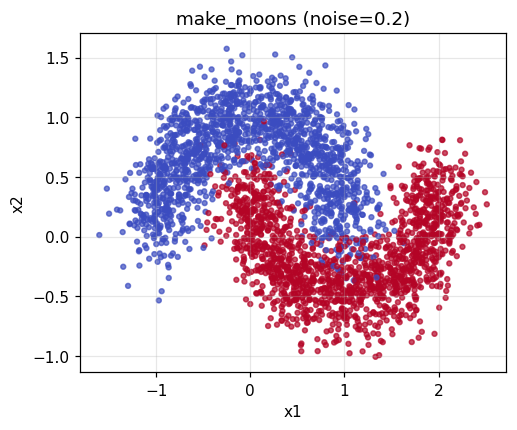

In [2]:
DATA_SEED = 42
X, y = make_moons(n_samples=3000, noise=0.2, random_state=DATA_SEED)
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.4, random_state=DATA_SEED, stratify=y)
X_val, X_te, y_val, y_te = train_test_split(X_tmp, y_tmp, test_size=0.5, random_state=DATA_SEED, stratify=y_tmp)

def to_t(a, dt): return torch.tensor(a, dtype=dt, device=DEVICE)
Xtr, ytr = to_t(X_tr, torch.float32), to_t(y_tr, torch.long)
Xval, yval = to_t(X_val, torch.float32), to_t(y_val, torch.long)
Xte, yte = to_t(X_te, torch.float32), to_t(y_te, torch.long)
print(f"train={len(Xtr)}  val={len(Xval)}  test={len(Xte)}")

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=10, alpha=0.7)
ax.set_title("make_moons (noise=0.2)"); ax.set_xlabel("x1"); ax.set_ylabel("x2")
fig.savefig("figures/00_dataset.png", bbox_inches="tight"); plt.show()

## 2. الموديل
نفس الشبكة بالظبط في كل التجارب: MLP بـ 3 hidden layers. الـ `seed` بيحدد الـ init، فنفس الـ seed = نفس نقطة البداية لكل optimizer.

In [3]:
def make_model(seed, dtype=torch.float32, device=DEVICE):
    torch.manual_seed(seed)
    m = nn.Sequential(
        nn.Linear(2, 64), nn.ReLU(),
        nn.Linear(64, 64), nn.ReLU(),
        nn.Linear(64, 64), nn.ReLU(),
        nn.Linear(64, 2),
    )
    return m.to(device=device, dtype=dtype)

def get_optimizer(name, params, lr, weight_decay=None):
    if name == "SGD":          return torch.optim.SGD(params, lr=lr)
    if name == "SGD+Momentum": return torch.optim.SGD(params, lr=lr, momentum=0.9)
    if name == "RMSprop":      return torch.optim.RMSprop(params, lr=lr)
    if name == "Adam":         return torch.optim.Adam(params, lr=lr)
    if name == "AdamW":        return torch.optim.AdamW(params, lr=lr, weight_decay=0.01 if weight_decay is None else weight_decay)
    if name == "Adam+L2":      return torch.optim.Adam(params, lr=lr, weight_decay=weight_decay or 0.0)  # coupled L2
    raise ValueError(name)

## 3. الـ Optimizers من الصفر (وإثبات إنها صح)
أفضل طريقة تثبت إنك فاهم optimizer إنك تكتبه. هنا الـ 5 في class واحد (~40 سطر)، وبعدين بنقارن الـ parameters بعد 50 خطوة مع `torch.optim` بدقة **float64**. لو الفرق أقل من `1e-7` يبقى الـ math مطابق.

| Optimizer | Update rule (مختصر) |
|---|---|
| SGD | `θ ← θ − lr·g` |
| Momentum | `v ← μ·v + g`  ;  `θ ← θ − lr·v` |
| RMSprop | `s ← α·s + (1−α)·g²`  ;  `θ ← θ − lr·g/(√s + ε)` |
| Adam | `m ← β₁m + (1−β₁)g`, `v ← β₂v + (1−β₂)g²`  ;  `θ ← θ − lr·m̂/(√v̂ + ε)` (مع bias correction) |
| AdamW | زي Adam + `θ ← θ·(1 − lr·λ)` **منفصلة** عن الـ gradient |

In [4]:
class ScratchOptimizer:
    def __init__(self, params, kind, lr, momentum=0.9, alpha=0.99,
                 betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0):
        self.params = list(params)
        self.kind, self.lr, self.mom, self.alpha = kind, lr, momentum, alpha
        self.b1, self.b2, self.eps, self.wd = betas[0], betas[1], eps, weight_decay
        self.state = [{} for _ in self.params]
        self.t = 0

    def zero_grad(self):
        for p in self.params: p.grad = None

    @torch.no_grad()
    def step(self):
        self.t += 1
        for p, s in zip(self.params, self.state):
            if p.grad is None: continue
            g = p.grad
            if self.kind == "sgd":
                p.add_(g, alpha=-self.lr)
            elif self.kind == "momentum":
                if "buf" not in s: s["buf"] = g.clone()
                else: s["buf"].mul_(self.mom).add_(g)
                p.add_(s["buf"], alpha=-self.lr)
            elif self.kind == "rmsprop":
                sq = s.setdefault("sq", torch.zeros_like(p))
                sq.mul_(self.alpha).addcmul_(g, g, value=1 - self.alpha)
                p.addcdiv_(g, sq.sqrt().add_(self.eps), value=-self.lr)
            elif self.kind in ("adam", "adamw"):
                if self.kind == "adamw":
                    p.mul_(1 - self.lr * self.wd)          # decoupled weight decay
                elif self.wd:
                    g = g + self.wd * p                    # coupled L2 (Adam+L2)
                m = s.setdefault("m", torch.zeros_like(p))
                v = s.setdefault("v", torch.zeros_like(p))
                m.mul_(self.b1).add_(g, alpha=1 - self.b1)
                v.mul_(self.b2).addcmul_(g, g, value=1 - self.b2)
                bc1, bc2 = 1 - self.b1 ** self.t, 1 - self.b2 ** self.t
                denom = (v.sqrt() / math.sqrt(bc2)).add_(self.eps)
                p.addcdiv_(m, denom, value=-self.lr / bc1)
            else:
                raise ValueError(self.kind)

In [5]:
def max_param_diff(scratch_kwargs, torch_factory, steps=50):
    Xd, yd = Xtr[:256].double().cpu(), ytr[:256].cpu()
    m1, m2 = make_model(0, torch.float64, "cpu"), make_model(0, torch.float64, "cpu")
    o1 = ScratchOptimizer(m1.parameters(), **scratch_kwargs)
    o2 = torch_factory(m2.parameters())
    for _ in range(steps):
        for m, o in ((m1, o1), (m2, o2)):
            o.zero_grad(); F.cross_entropy(m(Xd), yd).backward(); o.step()
    return max((a - b).abs().max().item() for a, b in zip(m1.parameters(), m2.parameters()))

checks = {
    "SGD":          (dict(kind="sgd", lr=0.05),                       lambda p: torch.optim.SGD(p, lr=0.05)),
    "SGD+Momentum": (dict(kind="momentum", lr=0.05, momentum=0.9),    lambda p: torch.optim.SGD(p, lr=0.05, momentum=0.9)),
    "RMSprop":      (dict(kind="rmsprop", lr=1e-3),                   lambda p: torch.optim.RMSprop(p, lr=1e-3)),
    "Adam":         (dict(kind="adam", lr=1e-3),                      lambda p: torch.optim.Adam(p, lr=1e-3)),
    "AdamW":        (dict(kind="adamw", lr=1e-3, weight_decay=0.1),   lambda p: torch.optim.AdamW(p, lr=1e-3, weight_decay=0.1)),
    "Adam+L2":      (dict(kind="adam", lr=1e-3, weight_decay=0.1),    lambda p: torch.optim.Adam(p, lr=1e-3, weight_decay=0.1)),
}
rows = []
for name, (kw, fac) in checks.items():
    d = max_param_diff(kw, fac)
    rows.append({"optimizer": name, "max |θ_scratch − θ_torch|": f"{d:.2e}", "match": d < 1e-7})
verify = pd.DataFrame(rows); display(verify)
assert verify["match"].all(), "Scratch implementation does not match torch.optim"

,optimizer,max |θ_scratch − θ_torch|,match
0,SGD,0.00e+00,True
1,SGD+Momentum,0.00e+00,True
2,RMSprop,0.00e+00,True
3,Adam,2.22e-16,True
4,AdamW,1.11e-16,True
5,Adam+L2,1.11e-16,True


## 4. حلقة التدريب (mini-batch)
- كل epoch بنعمل `randperm` جديد (shuffle) بـ generator مرتبط بالـ seed، عشان النتايج قابلة للتكرار.
- بنسجل train loss و val loss و val acc لكل epoch. الـ test بيتقاس **بس في التدريبات النهائية** (`final=True`) وفي آخر epoch، ومش بيدخل في أي قرار (LR أو λ).
- مفيش قياس وقت: الأرقام على داتا بالحجم ده بتبقى ضجيج (CUDA warm-up بيبوّظ أول تجربة). المقارنة هنا بالـ epochs والـ steps مش بالثواني.

In [6]:
def evaluate(model, X, y):
    model.eval()
    with torch.no_grad():
        logits = model(X)
        return F.cross_entropy(logits, y).item(), (logits.argmax(1) == y).float().mean().item()

def train(name, lr, seed, epochs=EPOCHS, batch_size=BATCH, weight_decay=None, keep_model=False, final=False):
    model = make_model(seed)
    opt = get_optimizer(name, model.parameters(), lr, weight_decay)
    gen = torch.Generator().manual_seed(seed)
    n = Xtr.shape[0]
    hist = {"train_loss": [], "val_loss": [], "val_acc": []}
    for _ in range(epochs):
        model.train()
        perm = torch.randperm(n, generator=gen).to(DEVICE)
        running = torch.zeros((), device=DEVICE)
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            opt.zero_grad(set_to_none=True)
            loss = F.cross_entropy(model(Xtr[idx]), ytr[idx])
            loss.backward(); opt.step()
            running += loss.detach() * len(idx)
        hist["train_loss"].append((running / n).item())
        vl, va = evaluate(model, Xval, yval)
        hist["val_loss"].append(vl); hist["val_acc"].append(va)
    if final:                                   # test is touched ONLY in the final runs
        hist["test_loss"], hist["test_acc"] = evaluate(model, Xte, yte)
    hist["weight_norm"] = math.sqrt(sum((p ** 2).sum().item() for p in model.parameters() if p.dim() > 1))
    return (hist, model) if keep_model else hist

## 5. LR sweep — كل optimizer بيدور على أحسن LR ليه
بنجرب 8 قيم LR × 5 optimizers × 3 seeds، ونختار على أساس **متوسط الـ validation loss** في آخر epoch. الـ seeds هنا (100–102) غير الـ seeds بتاعة المقارنة النهائية (0–4)، عشان مفيش تسريب بين الاختيار والتقييم.

In [7]:
LRS = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 3e-1]
SWEEP_SEEDS = [100, 101, 102]

rows = []
for name in OPTIMIZER_NAMES:
    for lr in LRS:
        for s in SWEEP_SEEDS:
            h = train(name, lr, s)
            rows.append({"optimizer": name, "lr": lr, "seed": s,
                         "val_loss": h["val_loss"][-1], "val_acc": h["val_acc"][-1]})
    print(f"sweep done: {name}")

sweep = pd.DataFrame(rows)
sweep["val_loss"] = sweep["val_loss"].fillna(np.inf)       # diverged run = worst
sweep_loss = sweep.groupby(["optimizer", "lr"])["val_loss"].mean().unstack(0)[OPTIMIZER_NAMES]
best_lr = sweep_loss.idxmin().to_dict()
robust_width = (sweep_loss <= 1.5 * sweep_loss.min()).sum().to_dict()
print("Best LR per optimizer:", best_lr)

sweep done: SGD
sweep done: SGD+Momentum
sweep done: RMSprop
sweep done: Adam
sweep done: AdamW
Best LR per optimizer: {'SGD': 0.03, 'SGD+Momentum': 0.003, 'RMSprop': 0.0003, 'Adam': 0.001, 'AdamW': 0.001}


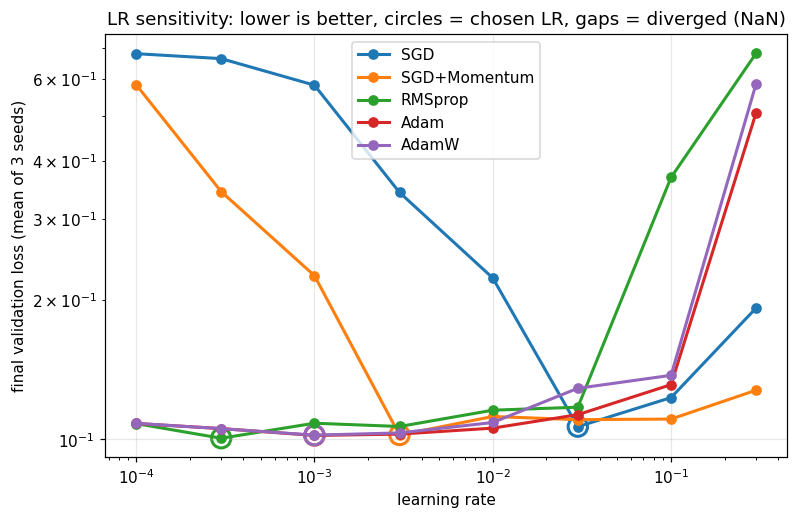

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
for name in OPTIMIZER_NAMES:
    curve = sweep_loss[name].replace(np.inf, np.nan)
    ax.plot(curve.index, curve.values, "o-", color=COLORS[name], label=name, lw=2)
    ax.scatter([best_lr[name]], [curve[best_lr[name]]], s=160, facecolors="none", edgecolors=COLORS[name], lw=2)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("learning rate"); ax.set_ylabel("final validation loss (mean of 3 seeds)")
ax.set_title("LR sensitivity: lower is better, circles = chosen LR, gaps = diverged (NaN)")
ax.legend()
fig.savefig("figures/01_lr_sensitivity.png", bbox_inches="tight"); plt.show()

## 6. المقارنة النهائية: أحسن LR لكل optimizer × 5 seeds

In [9]:
FINAL_SEEDS = [0, 1, 2, 3, 4]
final, models0 = {}, {}
for name in OPTIMIZER_NAMES:
    runs = []
    for s in FINAL_SEEDS:
        out = train(name, best_lr[name], s, keep_model=(s == FINAL_SEEDS[0]), final=True)
        if s == FINAL_SEEDS[0]: out, models0[name] = out
        runs.append(out)
    final[name] = runs
    print(f"final runs done: {name} (lr={best_lr[name]})")

final runs done: SGD (lr=0.03)
final runs done: SGD+Momentum (lr=0.003)
final runs done: RMSprop (lr=0.0003)
final runs done: Adam (lr=0.001)
final runs done: AdamW (lr=0.001)


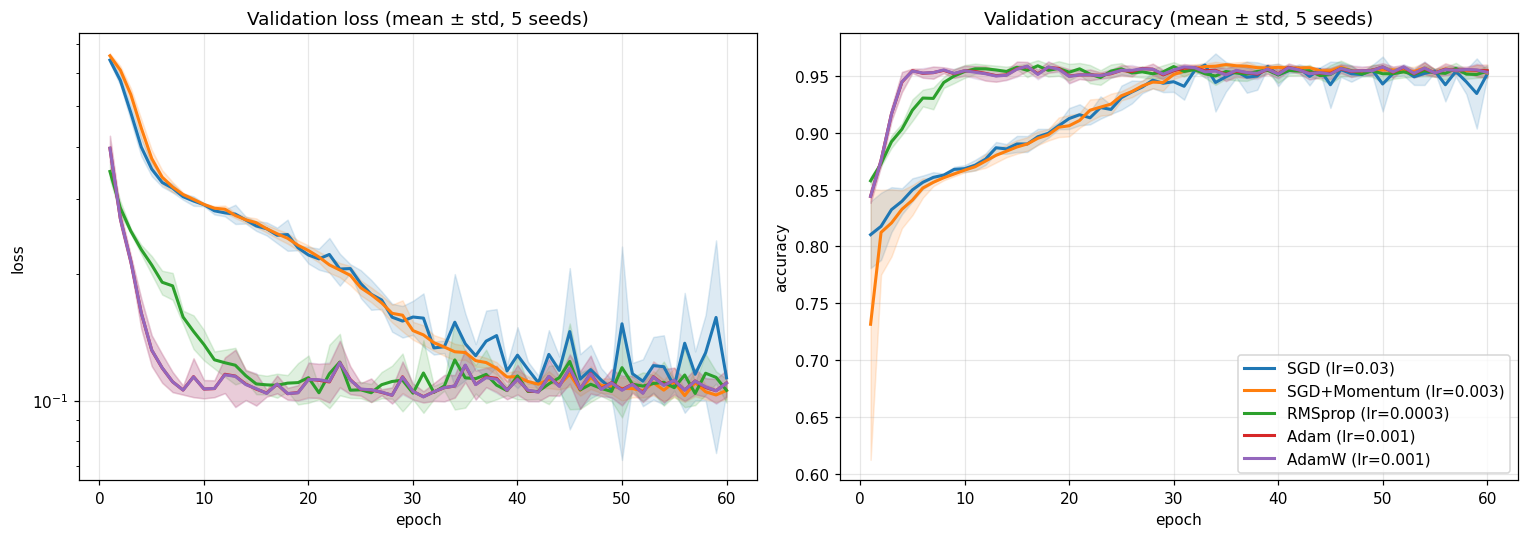

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name in OPTIMIZER_NAMES:
    for ax, key in zip(axes, ["val_loss", "val_acc"]):
        arr = np.array([r[key] for r in final[name]])
        mu, sd = arr.mean(0), arr.std(0)
        x = np.arange(1, arr.shape[1] + 1)
        ax.plot(x, mu, color=COLORS[name], lw=2, label=f"{name} (lr={best_lr[name]:g})")
        ax.fill_between(x, mu - sd, mu + sd, color=COLORS[name], alpha=0.15)
axes[0].set_yscale("log"); axes[0].set_title("Validation loss (mean ± std, 5 seeds)")
axes[1].set_title("Validation accuracy (mean ± std, 5 seeds)")
for ax in axes: ax.set_xlabel("epoch")
axes[0].set_ylabel("loss"); axes[1].set_ylabel("accuracy"); axes[1].legend(loc="lower right")
plt.tight_layout(); fig.savefig("figures/02_convergence.png", bbox_inches="tight"); plt.show()

In [11]:
def epochs_to(vals, thr=0.95):
    hit = np.where(np.array(vals) >= thr)[0]
    return hit[0] + 1 if len(hit) else np.nan

rows = []
for name in OPTIMIZER_NAMES:
    runs = final[name]
    ta = np.array([r["test_acc"] for r in runs]); tl = np.array([r["test_loss"] for r in runs])
    reach = np.array([epochs_to(r["val_acc"]) for r in runs]); ok = reach[~np.isnan(reach)]
    rows.append({
        "Optimizer": name,
        "Best LR": f"{best_lr[name]:g}",
        "Test acc (mean ± std)": f"{ta.mean():.4f} ± {ta.std():.4f}",
        "Test loss": f"{np.nanmean(tl):.4f}",
        "Epochs to 95% val-acc": f"{np.median(ok):.0f} ({len(ok)}/{len(runs)} seeds)" if len(ok) else "never",
        "LRs within 1.5x of best": f"{robust_width[name]}/{len(LRS)}",
        "_acc": ta.mean(), "_ep": np.median(ok) if len(ok) else np.inf, "_w": robust_width[name],
    })
summary = pd.DataFrame(rows)
display(summary.drop(columns=["_acc", "_ep", "_w"]).set_index("Optimizer"))

,Best LR,Test acc (mean ± std),Test loss,Epochs to 95% val-acc,LRs within 1.5x of best
Optimizer,,,,,
SGD,0.03,0.9660 ± 0.0075,0.0838,28 (5/5 seeds),2/8
SGD+Momentum,0.003,0.9723 ± 0.0053,0.0764,29 (5/5 seeds),5/8
RMSprop,0.0003,0.9720 ± 0.0029,0.0738,10 (5/5 seeds),6/8
Adam,0.001,0.9703 ± 0.0031,0.0763,5 (5/5 seeds),7/8
AdamW,0.001,0.9700 ± 0.0032,0.0761,5 (5/5 seeds),7/8


In [12]:
fastest  = summary.loc[summary["_ep"].idxmin(), "Optimizer"]
best_acc = summary.loc[summary["_acc"].idxmax(), "Optimizer"]
widest   = summary.loc[summary["_w"].idxmax(), "Optimizer"]
print(f"Fastest to 95% val-acc : {fastest}")
print(f"Highest mean test acc  : {best_acc}")
print(f"Most LR-robust (grid)  : {widest}")

def df_to_md(df):
    cols = list(df.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "|".join(["---"] * len(cols)) + "|"]
    for _, r in df.iterrows(): lines.append("| " + " | ".join(str(r[c]) for c in cols) + " |")
    return "\n".join(lines)

table = summary.drop(columns=["_acc", "_ep", "_w"])
with open("results/summary.md", "w") as f: f.write(df_to_md(table))
sweep_loss.to_csv("results/lr_sweep_val_loss.csv")
print("saved: results/summary.md , results/lr_sweep_val_loss.csv")

Fastest to 95% val-acc : Adam
Highest mean test acc  : SGD+Momentum
Most LR-robust (grid)  : Adam
saved: results/summary.md , results/lr_sweep_val_loss.csv


## 7. الـ Decision Boundary (seed 0)
الرسم على **الـ test points بس** عشان نشوف التعميم مش الحفظ.

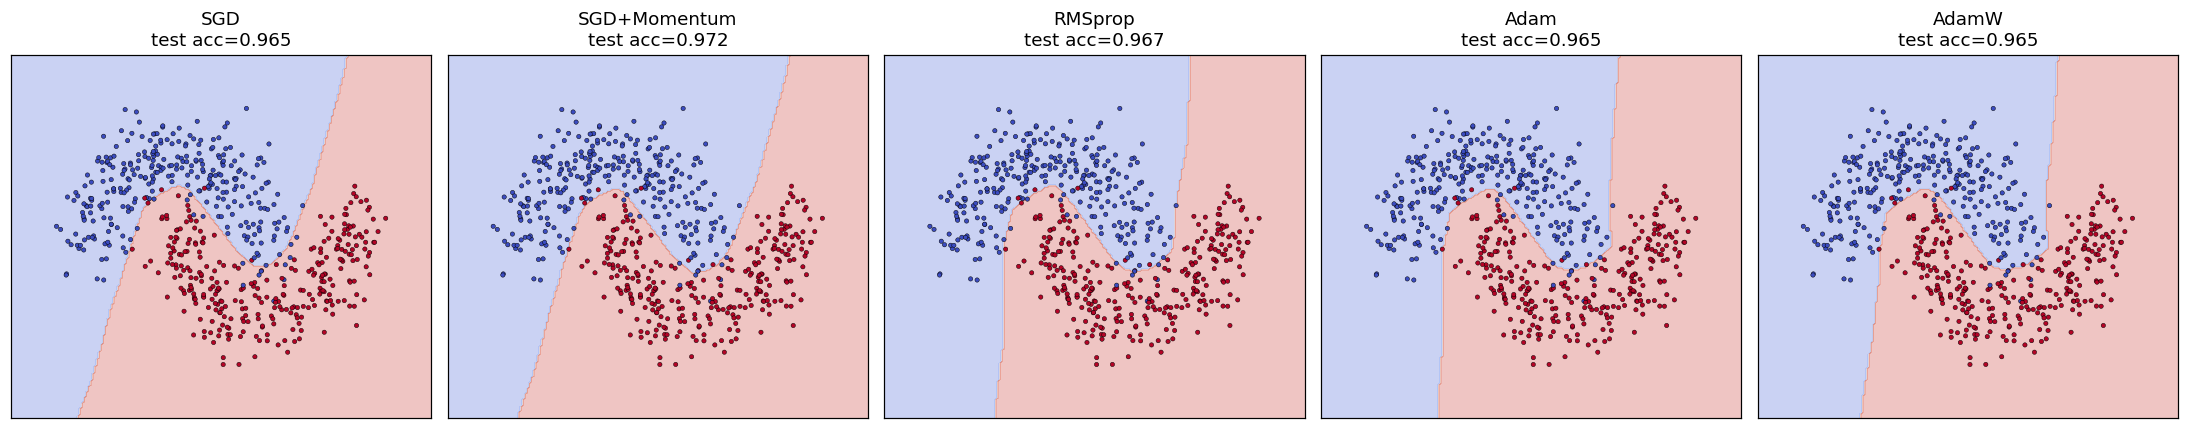

In [13]:
def plot_boundary(model, X, y, ax, title):
    pad = 0.5
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, 200),
                         np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, 200))
    grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32, device=DEVICE)
    model.eval()
    with torch.no_grad(): pred = model(grid).argmax(1).cpu().numpy().reshape(xx.shape)
    ax.contourf(xx, yy, pred, alpha=0.3, cmap="coolwarm")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=8, edgecolors="k", linewidths=0.3)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, name in zip(axes, OPTIMIZER_NAMES):
    plot_boundary(models0[name], X_te, y_te, ax, f"{name}\ntest acc={final[name][0]['test_acc']:.3f}")
plt.tight_layout(); fig.savefig("figures/03_decision_boundaries.png", bbox_inches="tight"); plt.show()

## 8. AdamW مش Adam: الفرق في الـ weight decay (مقارنة عادلة)
**مشكلة المقارنة عند نفس الـ λ:** الـ λ مش بنفس المعنى في الاتنين.
- **AdamW:** كل step بيضرب الـ weights في `(1 − lr·λ)`، يعني القوة الفعلية = `lr·λ` (صغيرة جداً).
- **Adam + L2:** الـ `λ·θ` بتتضاف للـ gradient وبعدين Adam بيعمل لها normalization بالـ `√v`، فلو الـ term ده بقى مسيطر الـ step بيبقى حوالي `lr` لكل parameter بغض النظر عن حجم λ.

عشان كده مقارنتهم عند نفس الـ λ بتوري اختلاف في **المقياس** قبل ما توري اختلاف في **الجودة**. الحل: **كل واحد بيدور على أحسن λ ليه** على الـ validation (3 seeds)، وبعدين نقيس الـ test في الـ final seeds.

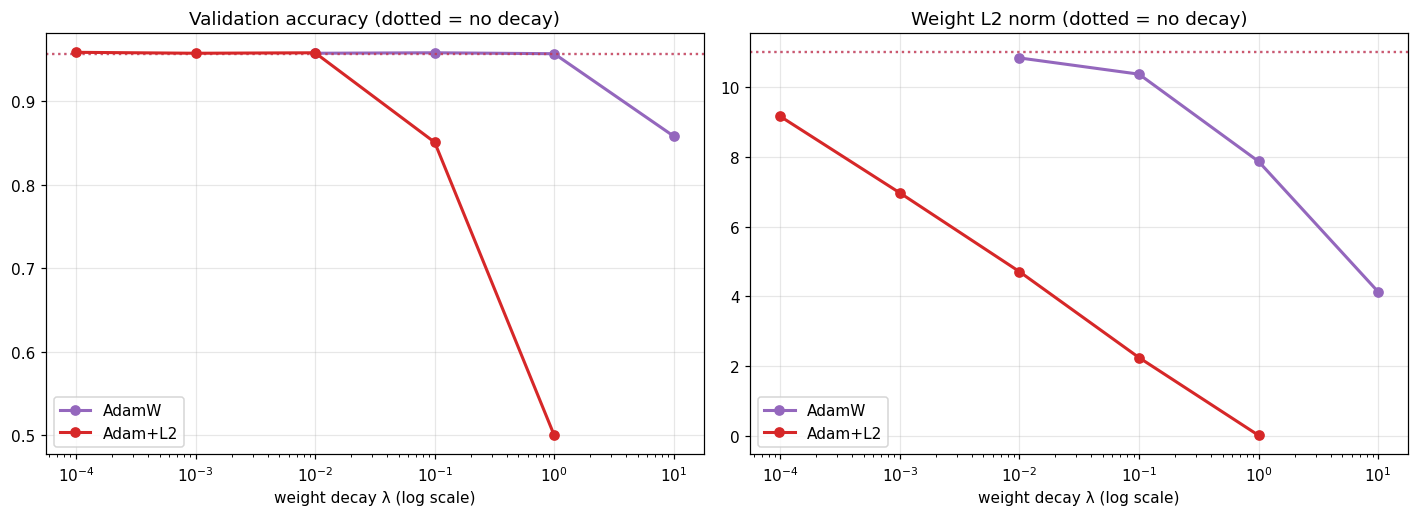

,variant,wd,val_loss,val_acc,weight_norm
0,Adam+L2,0.0000,0.102031,0.957222,10.998977
1,Adam+L2,0.0001,0.102675,0.958889,9.160785
2,Adam+L2,0.0010,0.102353,0.957778,6.965819
3,Adam+L2,0.0100,0.113860,0.958333,4.706764
4,Adam+L2,0.1000,0.409471,0.851111,2.240426
5,Adam+L2,1.0000,0.693149,0.500000,0.008989
6,AdamW,0.0000,0.102031,0.957222,10.998977
7,AdamW,0.0100,0.102189,0.957778,10.837959
8,AdamW,0.1000,0.101629,0.958333,10.371989
9,AdamW,1.0000,0.108051,0.957222,7.869209


In [14]:
ADAMW_GRID = [1e-2, 1e-1, 1.0, 10.0]
L2_GRID    = [1e-4, 1e-3, 1e-2, 1e-1, 1.0]
lr_adam = best_lr["Adam"]

rows = []
for variant, grid in [("Adam+L2", L2_GRID), ("AdamW", ADAMW_GRID)]:
    for wd in [0.0] + grid:
        for s in SWEEP_SEEDS:
            h = train(variant, lr_adam, s, weight_decay=wd)
            rows.append({"variant": variant, "wd": wd, "val_loss": h["val_loss"][-1],
                         "val_acc": h["val_acc"][-1], "weight_norm": h["weight_norm"]})
wd_df = pd.DataFrame(rows)
wd_df["val_loss"] = wd_df["val_loss"].fillna(np.inf)
wd_mean = wd_df.groupby(["variant", "wd"]).mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for variant, c in [("AdamW", "#9467bd"), ("Adam+L2", "#d62728")]:
    d = wd_mean[wd_mean.variant == variant]
    base, dd = d[d.wd == 0.0].iloc[0], d[d.wd > 0]
    for ax, key in zip(axes, ["val_acc", "weight_norm"]):
        ax.plot(dd.wd, dd[key], "o-", color=c, lw=2, label=variant)
        ax.axhline(base[key], color=c, ls=":", alpha=0.6)
for ax, t in zip(axes, ["Validation accuracy (dotted = no decay)", "Weight L2 norm (dotted = no decay)"]):
    ax.set_xscale("log"); ax.set_xlabel("weight decay λ (log scale)"); ax.set_title(t); ax.legend()
plt.tight_layout(); fig.savefig("figures/04_adamw_vs_adam_l2.png", bbox_inches="tight"); plt.show()
display(wd_mean)

In [15]:
# best λ per variant (on validation), then final test comparison on the final seeds
best_wd = {}
for variant in ["Adam+L2", "AdamW"]:
    d = wd_mean[(wd_mean.variant == variant) & (wd_mean.wd > 0)]
    best_wd[variant] = float(d.loc[d.val_loss.idxmin(), "wd"])
print("Best λ (validation):", best_wd)

rows = []
for label, name, wd in [("Adam (no decay)", "Adam", None),
                        (f"Adam+L2 (λ={best_wd['Adam+L2']:g})", "Adam+L2", best_wd["Adam+L2"]),
                        (f"AdamW (λ={best_wd['AdamW']:g})", "AdamW", best_wd["AdamW"])]:
    runs = [train(name, lr_adam, s, weight_decay=wd, final=True) for s in FINAL_SEEDS]
    ta = np.array([r["test_acc"] for r in runs]); wn = np.array([r["weight_norm"] for r in runs])
    rows.append({"Variant": label, "Test acc (mean ± std)": f"{ta.mean():.4f} ± {ta.std():.4f}",
                 "Weight norm": f"{wn.mean():.2f}"})
wd_final = pd.DataFrame(rows).set_index("Variant"); display(wd_final)
with open("results/adamw_vs_l2.md", "w") as f: f.write(df_to_md(wd_final.reset_index()))

Best λ (validation): {'Adam+L2': 0.001, 'AdamW': 0.1}


,Test acc (mean ± std),Weight norm
Variant,,
Adam (no decay),0.9703 ± 0.0031,11.29
Adam+L2 (λ=0.001),0.9720 ± 0.0039,7.08
AdamW (λ=0.1),0.9707 ± 0.0039,10.32


## 9. Intuition على دالة 2D: ليه كل optimizer بيتحرك بشكل مختلف؟
دالة ill-conditioned: `f(x, y) = ½(x² + 25y²)` يعني أرض مسطحة في `x` وحادة في `y`. بنستخدم الـ implementation بتاعنا من القسم 3. الـ LRs هنا اتحددت يدوياً للتوضيح، **مش** tuned زي القسم 5.

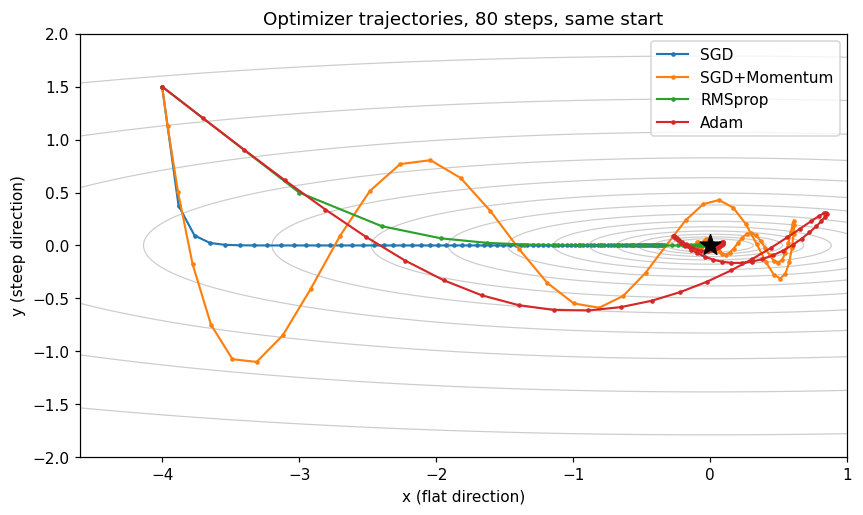

In [16]:
A = torch.tensor([1.0, 25.0])
def f(w): return 0.5 * (A * w * w).sum()

def trajectory(steps=80, **kw):
    w = torch.tensor([-4.0, 1.5], requires_grad=True)
    opt = ScratchOptimizer([w], **kw)
    path = [w.detach().clone()]
    for _ in range(steps):
        opt.zero_grad(); f(w).backward(); opt.step(); path.append(w.detach().clone())
    return torch.stack(path).numpy()

configs = {
    "SGD":          dict(kind="sgd", lr=0.03),
    "SGD+Momentum": dict(kind="momentum", lr=0.01, momentum=0.9),
    "RMSprop":      dict(kind="rmsprop", lr=0.1),
    "Adam":         dict(kind="adam", lr=0.3),
}
gx, gy = np.meshgrid(np.linspace(-4.6, 1.0, 300), np.linspace(-2, 2, 300))
gz = 0.5 * (gx ** 2 + 25 * gy ** 2)

fig, ax = plt.subplots(figsize=(9, 5))
ax.contour(gx, gy, gz, levels=np.geomspace(0.05, 40, 14), colors="gray", alpha=0.4, linewidths=0.8)
for name, kw in configs.items():
    p = trajectory(**kw)
    ax.plot(p[:, 0], p[:, 1], ".-", color=COLORS[name], label=name, lw=1.4, ms=4)
ax.scatter([0], [0], marker="*", s=200, c="k", zorder=5)
ax.set_xlabel("x (flat direction)"); ax.set_ylabel("y (steep direction)")
ax.set_title("Optimizer trajectories, 80 steps, same start"); ax.legend(); ax.grid(False)
fig.savefig("figures/05_trajectories.png", bbox_inches="tight"); plt.show()